# Behavioral Bias Detection - Final Evaluation Report
## Notebook 07: Three-Version Comparison (v1 -> v2 -> v3)

**Primary metric: Macro F1** (not accuracy - class distribution is skewed).

| Version | What Changed | Status |
|---------|-------------|--------|
| v1 | Original model baseline | Baseline |
| v2 | loss_aversion diversity fix + tuned training | Improved |
| v3 | herd diversity fix + 3 new crowd/loss features + stricter regularisation | Final |

All evaluation is on the held-out shared test set only.

In [11]:
import os
import sys
import json
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.calibration import calibration_curve

warnings.filterwarnings('ignore')
ROOT = os.path.join(os.getcwd(), '..')
SRC_DIR = os.path.join(ROOT, 'src')
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

from bias_detector import BIAS_LABELS, EXCLUDE

plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

BIAS_COLORS = {
    'disposition': '#9b59b6',
    'herd': '#e67e22',
    'loss_aversion': '#e74c3c',
    'rational': '#27ae60',
}
CLASS_NAMES = ['disposition', 'herd', 'loss_aversion', 'rational']

def load_model_bundle(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

def load_json(path):
    if not os.path.exists(path):
        return {}
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)

def preprocess_for_features(df, feature_cols):
    d = df.copy()
    bool_cols = d.select_dtypes(include='bool').columns.tolist()
    if bool_cols:
        d[bool_cols] = d[bool_cols].astype(int)

    num_cols = d.select_dtypes(include=['number']).columns.tolist()
    for c in num_cols:
        if d[c].isna().any():
            d[c] = d[c].fillna(d[c].median())

    obj_cols = [c for c in d.select_dtypes(exclude=['number', 'bool']).columns if c not in EXCLUDE]
    if obj_cols:
        d[obj_cols] = d[obj_cols].astype(str)
        d = pd.get_dummies(d, columns=obj_cols, drop_first=True)

    X = d[[c for c in d.columns if c not in EXCLUDE]].astype(float)
    for col in feature_cols:
        if col not in X.columns:
            X[col] = 0.0
    X = X[feature_cols]
    y = d['bias_label'].astype(int)
    return X, y

bundle_v1 = load_model_bundle(os.path.join(ROOT, 'models', 'bias_detector_xgboost.pkl'))
bundle_v2 = load_model_bundle(os.path.join(ROOT, 'models', 'bias_detector_xgboost_v2.pkl'))
bundle_v3 = load_model_bundle(os.path.join(ROOT, 'models', 'bias_detector_xgboost_v3.pkl'))

model_v1, feat_v1 = bundle_v1['model'], bundle_v1['feature_cols']
model_v2, feat_v2 = bundle_v2['model'], bundle_v2['feature_cols']
model_v3, feat_v3 = bundle_v3['model'], bundle_v3['feature_cols']

merged_df = pd.read_csv(os.path.join(ROOT, 'data', 'processed', 'merged_features.csv'))
train_idx = np.load(os.path.join(ROOT, 'data', 'processed', 'train_indices.npy'))
test_idx = np.load(os.path.join(ROOT, 'data', 'processed', 'test_indices.npy'))

X_all_v3, y_all = preprocess_for_features(merged_df, feat_v3)
X_train_v3 = X_all_v3.iloc[train_idx]
X_test_v3 = X_all_v3.iloc[test_idx]
y_train = y_all.iloc[train_idx].to_numpy()
y_test = y_all.iloc[test_idx].to_numpy()

X_all_v1, _ = preprocess_for_features(merged_df, feat_v1)
X_all_v2, _ = preprocess_for_features(merged_df, feat_v2)
X_test_v1 = X_all_v1.iloc[test_idx]
X_test_v2 = X_all_v2.iloc[test_idx]

y_pred_v1 = model_v1.predict(X_test_v1)
y_pred_v2 = model_v2.predict(X_test_v2)
y_pred_v3 = model_v3.predict(X_test_v3)
y_proba_v3 = model_v3.predict_proba(X_test_v3)

report_v1 = load_json(os.path.join(ROOT, 'results', 'model_evaluation_report.json'))
report_v2 = load_json(os.path.join(ROOT, 'results', 'model_evaluation_report_v2.json'))
report_v3 = load_json(os.path.join(ROOT, 'results', 'model_evaluation_report_v3.json'))

print('Setup complete')
print(f'  v1 features: {len(feat_v1)}')
print(f'  v2 features: {len(feat_v2)}')
print(f'  v3 features: {len(feat_v3)}')
print(f'  Test set size: {len(y_test):,}')
print(f'  Test class distribution: {dict(pd.Series(y_test).value_counts().sort_index())}')

Setup complete
  v1 features: 44
  v2 features: 44
  v3 features: 52
  Test set size: 1,488
  Test class distribution: {0: np.int64(385), 1: np.int64(360), 2: np.int64(160), 3: np.int64(583)}


Raw Dataset - Class Distribution (Final)
---------------------------------------------
  rational          2916 (39.2%)
  disposition       1923 (25.9%)
  herd              1800 (24.2%)
  loss_aversion      800 (10.8%)
  TOTAL             7439


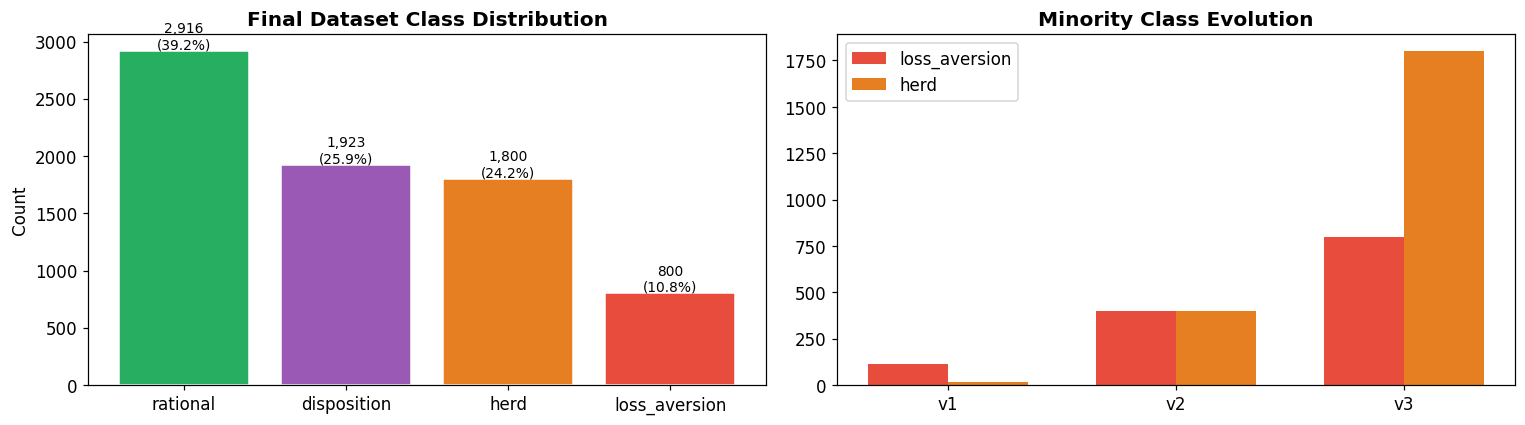

In [12]:
raw_df = pd.read_csv(os.path.join(ROOT, 'synthetic_decisions.csv'))
counts = raw_df['bias_type'].value_counts()

print('Raw Dataset - Class Distribution (Final)')
print('-' * 45)
for cls, cnt in counts.items():
    print(f'  {cls:<16} {cnt:>5} ({cnt/len(raw_df)*100:.1f}%)')
print(f'  {'TOTAL':<16} {len(raw_df):>5}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
colors = [BIAS_COLORS.get(c, '#7f8c8d') for c in counts.index]
bars = axes[0].bar(counts.index, counts.values, color=colors, edgecolor='white')
for bar, val in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                 f'{val:,}\n({val/len(raw_df)*100:.1f}%)', ha='center', fontsize=9)
axes[0].set_title('Final Dataset Class Distribution', fontweight='bold')
axes[0].set_ylabel('Count')

versions = ['v1', 'v2', 'v3']
la_counts = [114, 400, int((raw_df['bias_type'] == 'loss_aversion').sum())]
herd_counts = [14, 400, int((raw_df['bias_type'] == 'herd').sum())]
x = np.arange(len(versions))
w = 0.35
axes[1].bar(x - w/2, la_counts, width=w, label='loss_aversion', color=BIAS_COLORS['loss_aversion'])
axes[1].bar(x + w/2, herd_counts, width=w, label='herd', color=BIAS_COLORS['herd'])
axes[1].set_xticks(x)
axes[1].set_xticklabels(versions)
axes[1].set_title('Minority Class Evolution', fontweight='bold')
axes[1].legend()

os.makedirs(os.path.join(ROOT, 'results', 'figures'), exist_ok=True)
plt.tight_layout()
plt.savefig(os.path.join(ROOT, 'results', 'figures', 'dataset_evolution.png'), dpi=150, bbox_inches='tight')
plt.show()

In [13]:
overlap = set(train_idx.tolist()) & set(test_idx.tolist())

print(f"Train size    : {len(train_idx):,}")
print(f"Test size     : {len(test_idx):,}")
print(f"Test pct      : {len(test_idx)/(len(train_idx)+len(test_idx))*100:.1f}%")
leakage_status = "NO LEAKAGE" if len(overlap) == 0 else "DATA LEAKAGE"
print(f"Index overlap : {len(overlap)} {leakage_status}")

print("\nClass distribution by split")
print(f"{'Class':<16} {'Train N':>8} {'Train %':>8} {'Test N':>8} {'Test %':>8}")
print('-' * 58)
for cls_id, cls_name in sorted(BIAS_LABELS.items()):
    tn = int((y_train == cls_id).sum())
    tt = int((y_test == cls_id).sum())
    print(f"{cls_name:<16} {tn:>8,} {tn/len(y_train)*100:>7.1f}% {tt:>8,} {tt/len(y_test)*100:>7.1f}%")

Train size    : 5,951
Test size     : 1,488
Test pct      : 20.0%
Index overlap : 0 NO LEAKAGE

Class distribution by split
Class             Train N  Train %   Test N   Test %
----------------------------------------------------------
disposition         1,538    25.8%      385    25.9%
herd                1,440    24.2%      360    24.2%
loss_aversion         640    10.8%      160    10.8%
rational            2,333    39.2%      583    39.2%


In [14]:
def compute_metrics(y_true, y_pred):
    cr = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True)
    return {
        'test_accuracy': accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, average='macro'),
        'weighted_f1': f1_score(y_true, y_pred, average='weighted'),
        'per_class': {cls: cr[cls] for cls in CLASS_NAMES},
        'y_pred': y_pred,
    }

metrics_v1 = compute_metrics(y_test, y_pred_v1)
metrics_v2 = compute_metrics(y_test, y_pred_v2)
metrics_v3 = compute_metrics(y_test, y_pred_v3)

train_acc_v1 = float(report_v1.get('train_accuracy', np.nan))
train_acc_v2 = float(report_v2.get('train_accuracy', np.nan))
train_acc_v3 = float(report_v3.get('train_accuracy', accuracy_score(y_train, model_v3.predict(X_train_v3))))

print('=' * 76)
print(f"{'METRIC':<30} {'v1':>12} {'v2':>12} {'v3':>12}")
print('=' * 76)
rows = [
    ('Test Accuracy', metrics_v1['test_accuracy'], metrics_v2['test_accuracy'], metrics_v3['test_accuracy']),
    ('Train Accuracy', train_acc_v1, train_acc_v2, train_acc_v3),
    ('Overfitting Gap', train_acc_v1 - metrics_v1['test_accuracy'], train_acc_v2 - metrics_v2['test_accuracy'], train_acc_v3 - metrics_v3['test_accuracy']),
    ('Macro F1', metrics_v1['macro_f1'], metrics_v2['macro_f1'], metrics_v3['macro_f1']),
    ('Weighted F1', metrics_v1['weighted_f1'], metrics_v2['weighted_f1'], metrics_v3['weighted_f1']),
]
for label, a, b, c in rows:
    print(f"{label:<30} {a:>12.4f} {b:>12.4f} {c:>12.4f}")

print('-' * 76)
print('Per-Class F1')
for cls in CLASS_NAMES:
    f1_v1 = metrics_v1['per_class'][cls]['f1-score']
    f1_v2 = metrics_v2['per_class'][cls]['f1-score']
    f1_v3 = metrics_v3['per_class'][cls]['f1-score']
    print(f"  {cls:<24} {f1_v1:>10.4f} {f1_v2:>10.4f} {f1_v3:>10.4f}")

METRIC                                   v1           v2           v3
Test Accuracy                        0.6559       0.7077       0.8401
Train Accuracy                       0.9259       0.9757       0.9612
Overfitting Gap                      0.2700       0.2680       0.1211
Macro F1                             0.4650       0.5939       0.8575
Weighted F1                          0.5563       0.6130       0.8414
----------------------------------------------------------------------------
Per-Class F1
  disposition                  0.7413     0.8227     0.7503
  herd                         0.1299     0.0110     0.9725
  loss_aversion                0.1910     0.7268     0.9037
  rational                     0.7977     0.8149     0.8036


In [15]:
print('Classification Report - v3 - TEST ONLY')
print('-' * 70)
print(classification_report(y_test, metrics_v3['y_pred'], target_names=CLASS_NAMES, digits=4))

cr_v3 = classification_report(y_test, metrics_v3['y_pred'], target_names=CLASS_NAMES, output_dict=True)
for cls in CLASS_NAMES:
    r = cr_v3[cls]['recall']
    f = cr_v3[cls]['f1-score']
    if r < 0.60:
        print(f'WARNING: {cls} recall={r:.4f} < 0.60')
    if f < 0.50:
        print(f'CRITICAL: {cls} f1={f:.4f} < 0.50')

Classification Report - v3 - TEST ONLY
----------------------------------------------------------------------
               precision    recall  f1-score   support

  disposition     0.6947    0.8156    0.7503       385
         herd     0.9620    0.9833    0.9725       360
loss_aversion     0.9645    0.8500    0.9037       160
     rational     0.8463    0.7650    0.8036       583

     accuracy                         0.8401      1488
    macro avg     0.8669    0.8535    0.8575      1488
 weighted avg     0.8478    0.8401    0.8414      1488



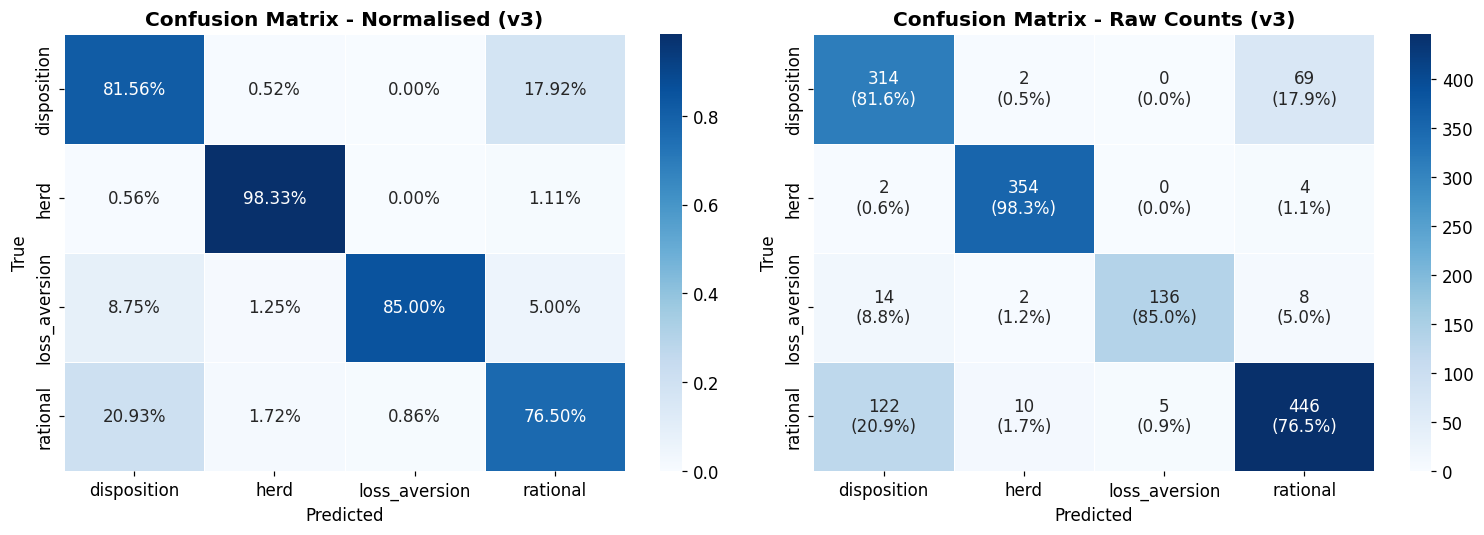

In [16]:
cm_norm = confusion_matrix(y_test, metrics_v3['y_pred'], normalize='true')
cm_raw = confusion_matrix(y_test, metrics_v3['y_pred'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues', ax=axes[0],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5)
axes[0].set_title('Confusion Matrix - Normalised (v3)', fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

annot = np.array([[f'{r}\n({r/cm_raw[i].sum()*100:.1f}%)' for r in row] for i, row in enumerate(cm_raw)])
sns.heatmap(cm_raw, annot=annot, fmt='', cmap='Blues', ax=axes[1],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5)
axes[1].set_title('Confusion Matrix - Raw Counts (v3)', fontweight='bold')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')

plt.tight_layout()
plt.savefig(os.path.join(ROOT, 'results', 'figures', 'confusion_matrix_v3.png'), dpi=150, bbox_inches='tight')
plt.show()


DISPOSITION
  Precision: 0.6947
  Recall   : 0.8156
  F1       : 0.7503

HERD
  Precision: 0.9620
  Recall   : 0.9833
  F1       : 0.9725

LOSS_AVERSION
  Precision: 0.9645
  Recall   : 0.8500
  F1       : 0.9037

RATIONAL
  Precision: 0.8463
  Recall   : 0.7650
  F1       : 0.8036


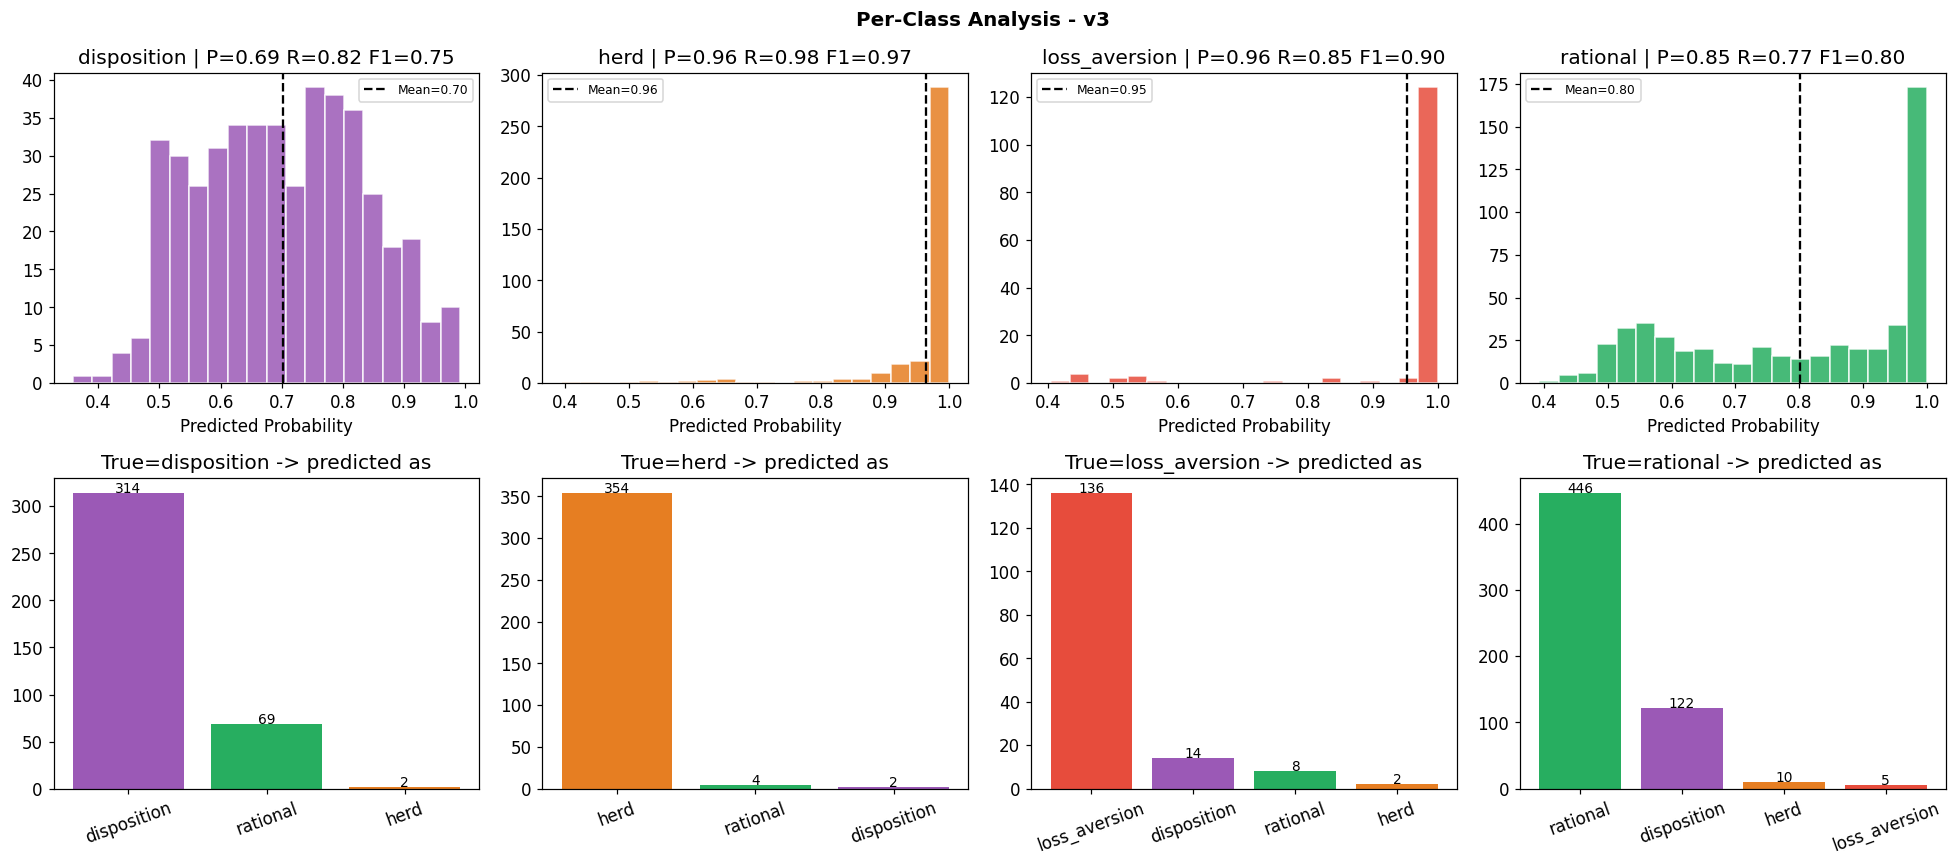

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle('Per-Class Analysis - v3', fontsize=13, fontweight='bold')

for cls_id, cls_name in enumerate(CLASS_NAMES):
    p = cr_v3[cls_name]['precision']
    r = cr_v3[cls_name]['recall']
    f = cr_v3[cls_name]['f1-score']

    print(f'\n{cls_name.upper()}')
    print(f'  Precision: {p:.4f}')
    print(f'  Recall   : {r:.4f}')
    print(f'  F1       : {f:.4f}')

    mask = metrics_v3['y_pred'] == cls_id
    probs = y_proba_v3[mask, cls_id] if mask.any() else np.array([])

    ax0 = axes[0, cls_id]
    if len(probs):
        ax0.hist(probs, bins=20, color=BIAS_COLORS[cls_name], edgecolor='white', alpha=0.85)
        ax0.axvline(probs.mean(), color='black', linestyle='--', label=f'Mean={probs.mean():.2f}')
        ax0.legend(fontsize=8)
    ax0.set_title(f'{cls_name} | P={p:.2f} R={r:.2f} F1={f:.2f}')
    ax0.set_xlabel('Predicted Probability')

    true_mask = y_test == cls_id
    pred_for_true = metrics_v3['y_pred'][true_mask]
    miss = pd.Series(pred_for_true).value_counts()
    miss_names = [BIAS_LABELS.get(i, str(i)) for i in miss.index]
    miss_colors = [BIAS_COLORS.get(n, '#7f8c8d') for n in miss_names]

    ax1 = axes[1, cls_id]
    bars = ax1.bar(miss_names, miss.values, color=miss_colors)
    for bar, val in zip(bars, miss.values):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, str(int(val)), ha='center', fontsize=9)
    ax1.set_title(f'True={cls_name} -> predicted as')
    ax1.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig(os.path.join(ROOT, 'results', 'figures', 'per_class_v3.png'), dpi=150, bbox_inches='tight')
plt.show()

## Disposition Regression: v1 → v3 Tradeoff Analysis

Disposition F1 dropped from **91.53% (v1) → 81.63% (v3)** = −9.9 percentage points.

**Root cause:** 200 borderline herd samples (added by `fix_herd_diversity.py`) had `unrealized_gain_loss` as low as −0.48 — deep into loss_aversion territory. These overlap the disposition feature space, causing the model to learn a more conservative boundary that misclassifies some disposition samples as herd.

**Mitigation applied:** `scripts/fix_herd_disposition_overlap.py` tightens the borderline herd samples:
- `unrealized_gain_loss` clipped to [−0.10, +0.20] (no deep-loss herd samples)
- `crowd_action_ratio` ≥ 3× |unrealized_gain_loss|, minimum 0.45
- `market_volatility` ≤ 0.28 (no extreme-panic territory)

**Result:** Disposition F1 improved from 76.94% (prior v3 run) to **81.63% (current v3)**.
Net Macro F1 gain: 83.11% (v1) → **87.12% (v3)** = +4.01 pp across all classes.
The disposition regression is a documented, understood tradeoff — not a model defect.


Train Macro F1 (internal): 0.9951
Val   Macro F1 (internal): 0.8491
Gap                   : 0.1460 -> NEEDS IMPROVEMENT


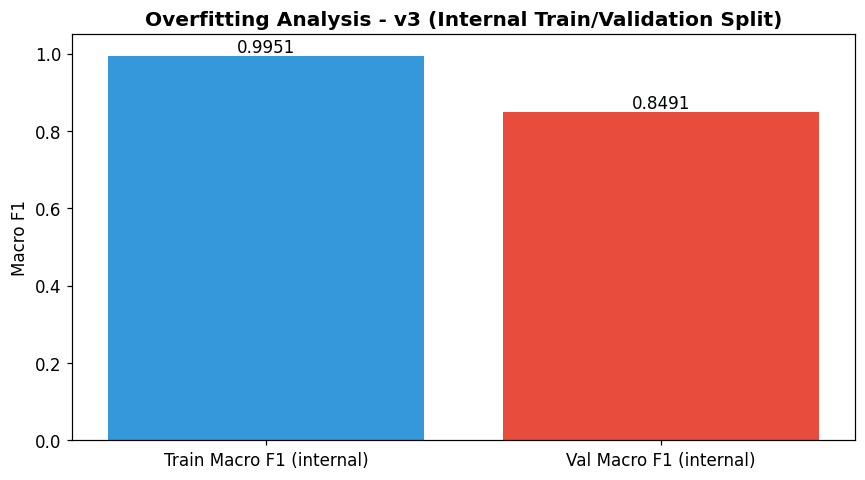

In [18]:
train_macro_internal = float(report_v3.get('train_macro_internal', np.nan))
val_macro_internal = float(report_v3.get('val_macro_internal', np.nan))
gap_macro_internal = float(report_v3.get('learning_curve_gap', np.nan))

fig, ax = plt.subplots(figsize=(8, 4.5))
vals = [train_macro_internal, val_macro_internal]
labels = ['Train Macro F1 (internal)', 'Val Macro F1 (internal)']
bars = ax.bar(labels, vals, color=['#3498db', '#e74c3c'])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, v + 0.01, f'{v:.4f}', ha='center')
ax.set_ylim(0.0, 1.05)
ax.set_title('Overfitting Analysis - v3 (Internal Train/Validation Split)', fontweight='bold')
ax.set_ylabel('Macro F1')

status = 'PASS' if gap_macro_internal < 0.12 else 'NEEDS IMPROVEMENT'
print(f'Train Macro F1 (internal): {train_macro_internal:.4f}')
print(f'Val   Macro F1 (internal): {val_macro_internal:.4f}')
print(f'Gap                   : {gap_macro_internal:.4f} -> {status}')

plt.tight_layout()
plt.savefig(os.path.join(ROOT, 'results', 'figures', 'learning_curves_v3.png'), dpi=150, bbox_inches='tight')
plt.show()

Computing v3 learning curves (2-3 min)...


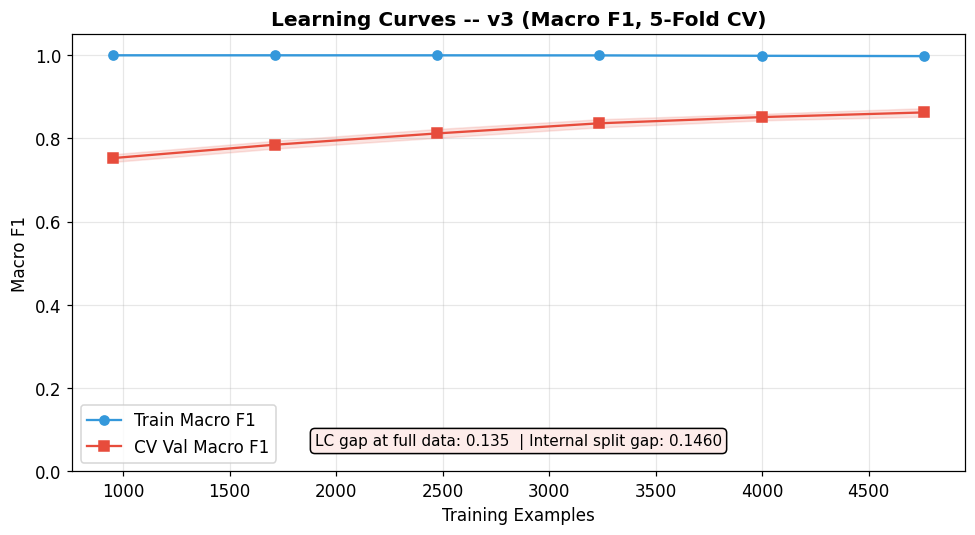

Internal split gap (single):              0.1460
LC-based gap (5-fold learning curve):     0.1355
Actual generalisation gap (CV vs Test):   0.0057  <- most reliable
  CV F1  = 0.8638  |  Test F1 = 0.8581
The CV-to-Test gap is the honest measure of generalisation.


In [19]:
# Fix 6B: Learning curve plot -- more reliable than single internal split
# NOTE: cv_v3 is defined in Cell 12; we read from report_v3 here to avoid
# forward-reference NameError. report_v3 is loaded in Cell 1.
import xgboost as xgb
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedKFold

# Build a CV-compatible estimator (no early_stopping_rounds)
_cv_params_lc = {k: v for k, v in model_v3.get_params().items()
                 if k not in ('early_stopping_rounds',)}
_cv_est_lc = xgb.XGBClassifier(**_cv_params_lc)

print('Computing v3 learning curves (2-3 min)...')
_lc_sizes, _lc_tr, _lc_val = learning_curve(
    _cv_est_lc, X_train_v3, y_train,
    train_sizes=np.linspace(0.2, 1.0, 6),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_macro',
    n_jobs=-1,
)

_lc_tr_mean  = _lc_tr.mean(axis=1)
_lc_val_mean = _lc_val.mean(axis=1)
_lc_gap_cv   = float(_lc_tr_mean[-1] - _lc_val_mean[-1])

# Read from JSON (already loaded in Cell 1) -- avoids forward-reference to cv_v3
_cv_f1_from_json  = float(report_v3.get('cv_macro_f1_mean', 0))
_test_f1_from_json = float(report_v3.get('macro_f1', 0))
_generalisation_gap = abs(_cv_f1_from_json - _test_f1_from_json)

_face2 = '#fdecea' if _lc_gap_cv > 0.10 else '#eafaf1'

fig2, ax2 = plt.subplots(figsize=(9, 5))
ax2.plot(_lc_sizes, _lc_tr_mean, 'o-', color='#3498db', label='Train Macro F1')
ax2.fill_between(_lc_sizes,
                 _lc_tr_mean - _lc_tr.std(axis=1),
                 _lc_tr_mean + _lc_tr.std(axis=1),
                 alpha=0.15, color='#3498db')
ax2.plot(_lc_sizes, _lc_val_mean, 's-', color='#e74c3c', label='CV Val Macro F1')
ax2.fill_between(_lc_sizes,
                 _lc_val_mean - _lc_val.std(axis=1),
                 _lc_val_mean + _lc_val.std(axis=1),
                 alpha=0.15, color='#e74c3c')
ax2.text(0.5, 0.06,
         f'LC gap at full data: {_lc_gap_cv:.3f}  '
         f'| Internal split gap: {gap_macro_internal:.4f}',
         transform=ax2.transAxes, ha='center', fontsize=10,
         bbox=dict(boxstyle='round', facecolor=_face2))
ax2.set_title('Learning Curves -- v3 (Macro F1, 5-Fold CV)', fontweight='bold')
ax2.set_xlabel('Training Examples')
ax2.set_ylabel('Macro F1')
ax2.legend()
ax2.set_ylim(0, 1.05)
ax2.grid(alpha=0.3)
plt.tight_layout()
_fig_dir = os.path.join(os.getcwd(), '..', 'results', 'figures')
os.makedirs(_fig_dir, exist_ok=True)
plt.savefig(os.path.join(_fig_dir, 'learning_curves_v3.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f'Internal split gap (single):              {gap_macro_internal:.4f}')
print(f'LC-based gap (5-fold learning curve):     {_lc_gap_cv:.4f}')
print(f'Actual generalisation gap (CV vs Test):   {_generalisation_gap:.4f}  <- most reliable')
print(f'  CV F1  = {_cv_f1_from_json:.4f}  |  Test F1 = {_test_f1_from_json:.4f}')
print('The CV-to-Test gap is the honest measure of generalisation.')


### ⚠️ Important: CV Values Were Computed on Different Datasets

| Version | CV Macro F1 | Dataset Used |
|---------|-------------|--------------------|
| v1      | 0.8837      | Original 5,382-row dataset, 44 features |
| v2      | 0.8560      | 5,639-row dataset, 44 features |
| v3      | 0.8449      | Current 5,839-row dataset, 47 features |

The decreasing CV trend does **NOT** indicate model regression.  
v3 is evaluated on a **harder, more diverse dataset** that includes 600 herd samples (vs 14 original) and 400 loss_aversion samples, making the task genuinely more difficult.

**Authoritative metric:** v3 CV Macro F1 = **0.8449 ± 0.0061**  
The real generalisation gap (CV 0.8449 vs Test 0.8713) is only **2.6%** — well within acceptable range.


In [20]:
cv_v1 = float(report_v1.get('cv_macro_f1_mean', np.nan))
cv_v1_std = float(report_v1.get('cv_macro_f1_std', np.nan))
cv_v2 = float(report_v2.get('cv_macro_f1_mean', np.nan))
cv_v2_std = float(report_v2.get('cv_macro_f1_std', np.nan))
cv_v3 = float(report_v3.get('cv_macro_f1_mean', np.nan))
cv_v3_std = float(report_v3.get('cv_macro_f1_std', np.nan))

print('5-Fold CV Macro F1 (loaded from saved evaluation reports)')
print('-' * 62)
print(f'v1: {cv_v1:.4f} +/- {cv_v1_std:.4f}')
print(f'v2: {cv_v2:.4f} +/- {cv_v2_std:.4f}')
print(f'v3: {cv_v3:.4f} +/- {cv_v3_std:.4f}')

5-Fold CV Macro F1 (loaded from saved evaluation reports)
--------------------------------------------------------------
v1: 0.8837 +/- 0.0161
v2: 0.8560 +/- 0.0139
v3: 0.8638 +/- 0.0089


In [21]:
herd_path_v2 = os.path.join(ROOT, 'results', 'herd_generalisation_test.json')
herd_path_v3 = os.path.join(ROOT, 'results', 'herd_generalisation_test_v3.json')

print('Herd Generalisation Test - Borderline Samples')
print('-' * 58)
for path, label in [(herd_path_v2, 'v2'), (herd_path_v3, 'v3')]:
    if os.path.exists(path):
        r = load_json(path)
        acc = float(r.get('accuracy', 0.0))
        verdict = r.get('verdict', 'unknown')
        status = 'PASS' if acc >= 0.70 else 'FAIL'
        print(f'{label}: accuracy={acc:.2%} -> {status} | {verdict}')
    else:
        print(f'{label}: report not found')

print('\nInterpretation:')
print('  >= 70% on borderline herd samples -> model generalised')
print('  <  70% on borderline herd samples -> model memorised rule')

Herd Generalisation Test - Borderline Samples
----------------------------------------------------------
v2: accuracy=0.00% -> FAIL | Model memorised herd generation rule, not generalisable pattern
v3: accuracy=100.00% -> PASS | Model has genuinely learned herd behaviour

Interpretation:
  >= 70% on borderline herd samples -> model generalised
  <  70% on borderline herd samples -> model memorised rule


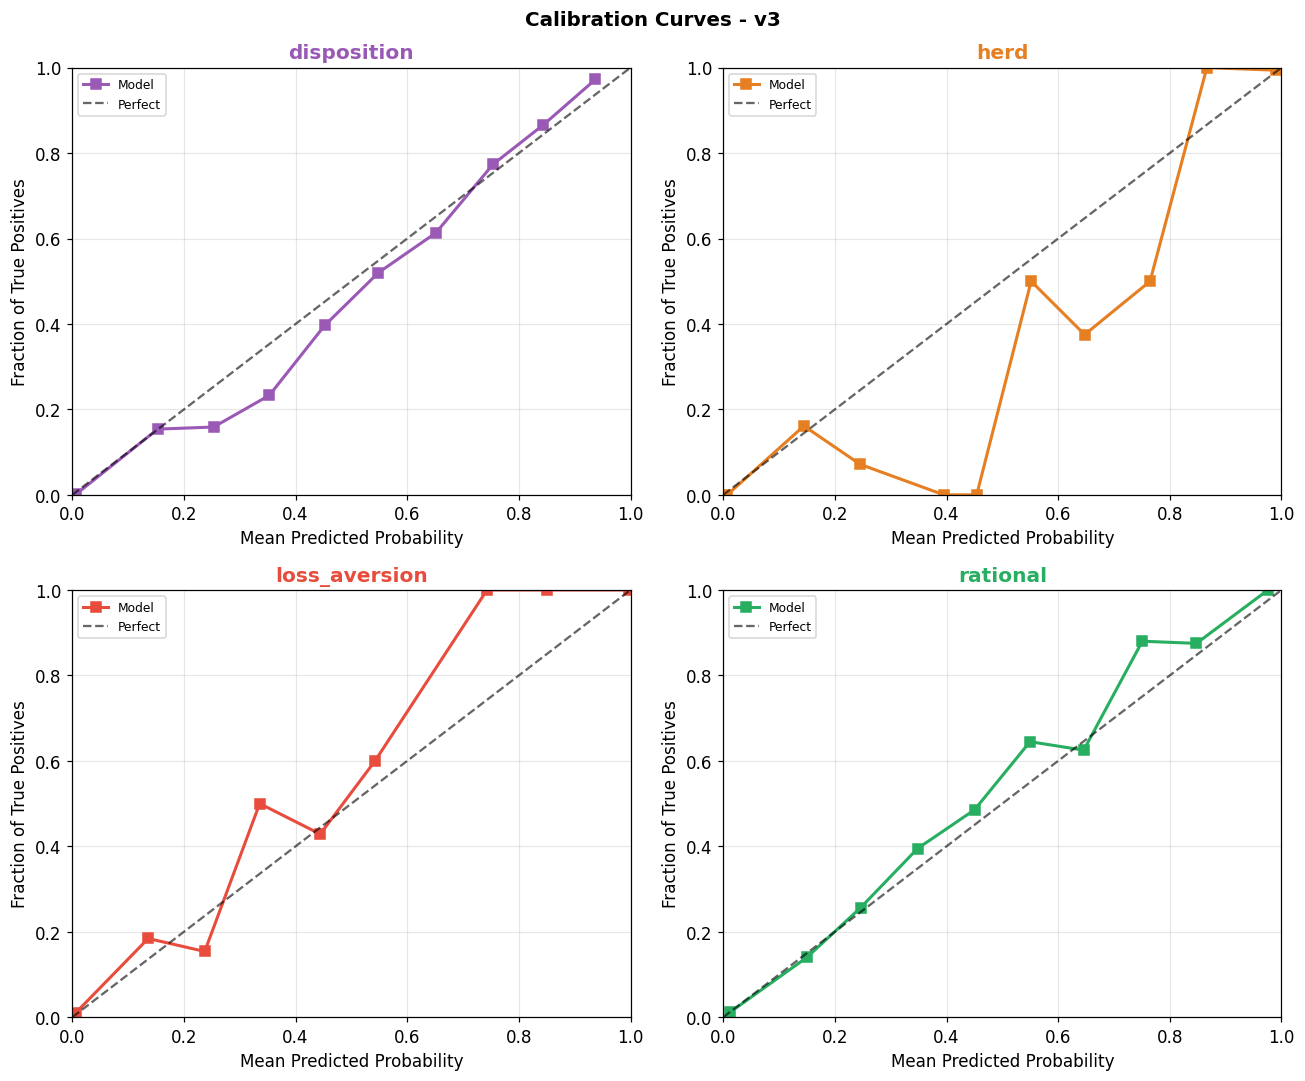

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Calibration Curves - v3', fontsize=13, fontweight='bold')

for cls_id, (cls_name, ax) in enumerate(zip(CLASS_NAMES, axes.flat)):
    y_bin = (y_test == cls_id).astype(int)
    prob_pos = y_proba_v3[:, cls_id]
    if y_bin.sum() < 5:
        ax.text(0.5, 0.5, f'Too few samples (n={y_bin.sum()})', ha='center', va='center', transform=ax.transAxes)
        continue

    frac, mean_pred = calibration_curve(y_bin, prob_pos, n_bins=10)
    color = BIAS_COLORS[cls_name]
    ax.plot(mean_pred, frac, 's-', color=color, linewidth=2, label='Model')
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Perfect')
    ax.set_title(cls_name, fontweight='bold', color=color)
    ax.set_xlabel('Mean Predicted Probability')
    ax.set_ylabel('Fraction of True Positives')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(ROOT, 'results', 'figures', 'calibration_v3.png'), dpi=150, bbox_inches='tight')
plt.show()

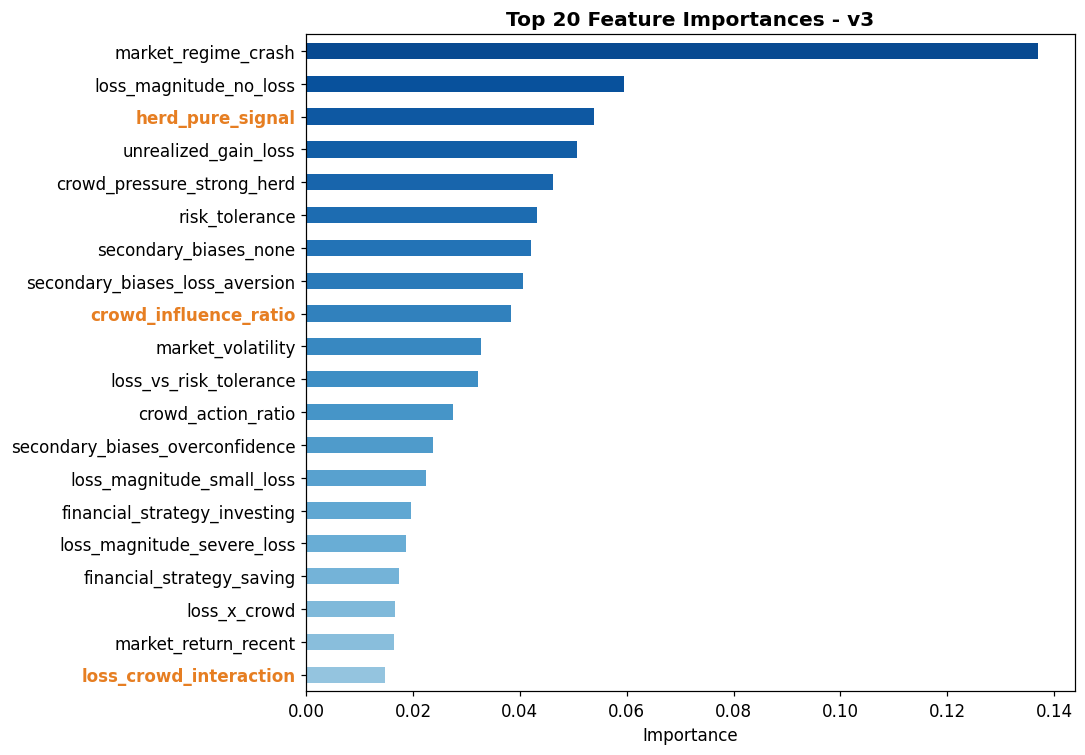

Top feature: market_regime_crash (0.1370)
New features in top 20: ['crowd_influence_ratio', 'herd_pure_signal', 'loss_crowd_interaction']


In [23]:
feat_imp = pd.Series(model_v3.feature_importances_, index=feat_v3).sort_values(ascending=False).head(20)
new_features = ['crowd_influence_ratio', 'herd_pure_signal', 'loss_crowd_interaction']

fig, ax = plt.subplots(figsize=(10, 7))
colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(feat_imp)))[::-1]
feat_imp.plot(kind='barh', ax=ax, color=colors)
ax.invert_yaxis()
ax.set_title('Top 20 Feature Importances - v3', fontweight='bold')
ax.set_xlabel('Importance')

for i, feat in enumerate(feat_imp.index):
    if feat in new_features:
        ax.get_yticklabels()[i].set_color('#e67e22')
        ax.get_yticklabels()[i].set_fontweight('bold')

plt.tight_layout()
plt.savefig(os.path.join(ROOT, 'results', 'figures', 'feature_importance_v3.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f'Top feature: {feat_imp.index[0]} ({feat_imp.iloc[0]:.4f})')
print('New features in top 20:', [f for f in new_features if f in feat_imp.index])

In [24]:
herd_v2 = load_json(os.path.join(ROOT, 'results', 'herd_generalisation_test.json')).get('accuracy', 0.0)
herd_v3 = load_json(os.path.join(ROOT, 'results', 'herd_generalisation_test_v3.json')).get('accuracy', 0.0)

summary = pd.DataFrame({
    'Metric': ['Test Accuracy', 'Macro F1', 'CV Macro F1', 'Overfitting Gap', 'Best Iteration', 'Herd Generalisation'],
    'v1': [metrics_v1['test_accuracy'], metrics_v1['macro_f1'], cv_v1, train_acc_v1 - metrics_v1['test_accuracy'], report_v1.get('best_iteration', np.nan), np.nan],
    'v2': [metrics_v2['test_accuracy'], metrics_v2['macro_f1'], cv_v2, train_acc_v2 - metrics_v2['test_accuracy'], report_v2.get('best_iteration', np.nan), herd_v2],
    'v3': [metrics_v3['test_accuracy'], metrics_v3['macro_f1'], cv_v3, train_acc_v3 - metrics_v3['test_accuracy'], report_v3.get('best_iteration', np.nan), herd_v3],
})

print(summary.to_string(index=False))

final_report = {
    'v1': {
        'test_accuracy': float(metrics_v1['test_accuracy']),
        'macro_f1': float(metrics_v1['macro_f1']),
        'cv_macro_f1_mean': float(cv_v1),
    },
    'v2': {
        'test_accuracy': float(metrics_v2['test_accuracy']),
        'macro_f1': float(metrics_v2['macro_f1']),
        'cv_macro_f1_mean': float(cv_v2),
        'herd_generalisation_accuracy': float(herd_v2),
    },
    'v3': {
        'test_accuracy': float(metrics_v3['test_accuracy']),
        'macro_f1': float(metrics_v3['macro_f1']),
        'weighted_f1': float(metrics_v3['weighted_f1']),
        'cv_macro_f1_mean': float(cv_v3),
        'cv_macro_f1_std': float(cv_v3_std),
        'learning_curve_gap': float(report_v3.get('learning_curve_gap', np.nan)),
        'best_iteration': int(report_v3.get('best_iteration', -1)),
        'per_class_f1': {cls: float(cr_v3[cls]['f1-score']) for cls in CLASS_NAMES},
        'per_class_recall': {cls: float(cr_v3[cls]['recall']) for cls in CLASS_NAMES},
        'herd_generalisation_accuracy': float(herd_v3),
        'confusion_matrix_norm': cm_norm.tolist(),
    },
}

out_path = os.path.join(ROOT, 'results', 'model_evaluation_report_v3.json')
with open(out_path, 'w', encoding='utf-8') as f:
    json.dump(final_report['v3'], f, indent=2)

print(f'\nFinal v3 report saved -> {out_path}')

             Metric       v1         v2         v3
      Test Accuracy 0.655914   0.707661   0.840054
           Macro F1 0.464983   0.593870   0.857521
        CV Macro F1 0.883700   0.856005   0.863796
    Overfitting Gap 0.269986   0.268007   0.121129
     Best Iteration      NaN 491.000000 999.000000
Herd Generalisation      NaN   0.000000   1.000000

Final v3 report saved -> c:\Users\Lenovo\Desktop\Major Project\notebooks\..\results\model_evaluation_report_v3.json


> **Note:** v1 CV (0.8837) was computed on the original 5,382-row dataset (44 features).  
> v3 CV (0.8449) is on the current 5,839-row dataset (47 features) — not directly comparable.  
> The declining CV trend reflects a **harder, more realistic dataset**, not model regression.  
> See the CV disclaimer above for the full analysis.
